In [13]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados 

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs; 
# 2 - para GoogleColab 
carga_dados = 1
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(io.BytesIO(uploaded['Dataset1.csv']))

df

,Data,Preco
0,7/1/2009 0:00,14.25
1,7/1/2009 1:00,8.43
2,7/1/2009 2:00,1.88
3,7/1/2009 3:00,11.00
4,7/1/2009 4:00,4.21
...,...,...
1003,8/11/2009 19:00,33.12
1004,8/11/2009 20:00,38.14
1005,8/11/2009 21:00,34.04
1006,8/11/2009 22:00,20.80


In [15]:
df['Preco'].describe()

count    1008.000000
mean       19.642411
std        14.662304
min         0.000000
25%         6.770000
50%        18.995000
75%        29.710000
max       237.760000
Name: Preco, dtype: float64

In [17]:
df['DateTime'] = pd.to_datetime(df['Data'])
df

,Data,Preco,DateTime
0,7/1/2009 0:00,14.25,2009-07-01 00:00:00
1,7/1/2009 1:00,8.43,2009-07-01 01:00:00
2,7/1/2009 2:00,1.88,2009-07-01 02:00:00
3,7/1/2009 3:00,11.00,2009-07-01 03:00:00
4,7/1/2009 4:00,4.21,2009-07-01 04:00:00
...,...,...,...
1003,8/11/2009 19:00,33.12,2009-08-11 19:00:00
1004,8/11/2009 20:00,38.14,2009-08-11 20:00:00
1005,8/11/2009 21:00,34.04,2009-08-11 21:00:00
1006,8/11/2009 22:00,20.80,2009-08-11 22:00:00


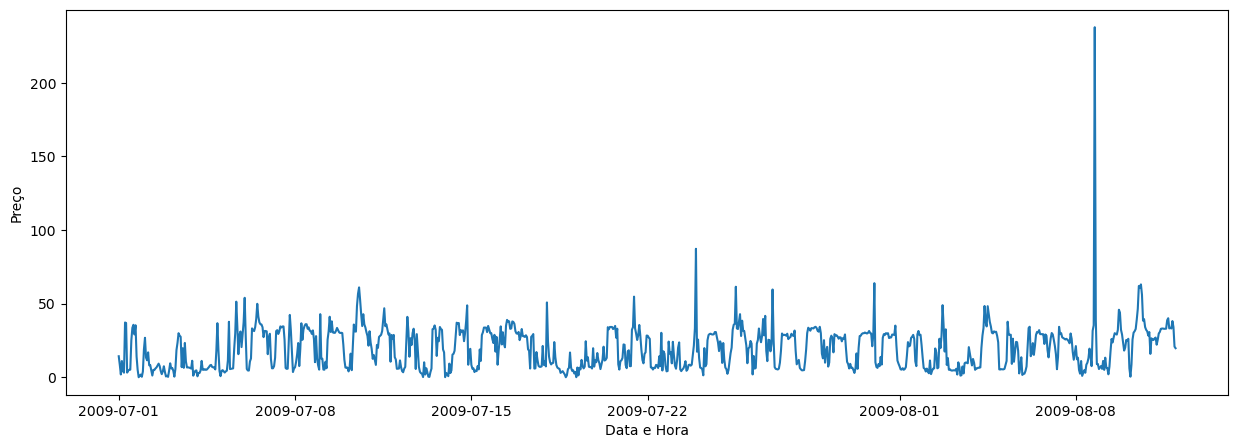

In [19]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.ylabel('Preço')
plt.xlabel('Data e Hora')
plt.show()

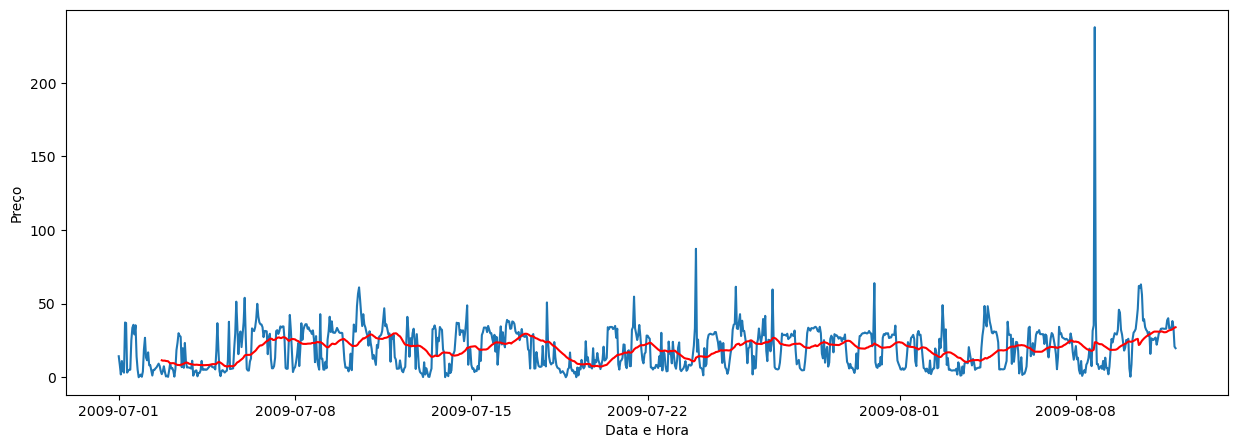

In [21]:
# Média Móvel como Suavização de Dados
tamanho_janela = 42
df['MA_Suavizacao'] = df['Preco'].rolling(tamanho_janela).mean()

plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df['DateTime'], df['MA_Suavizacao'], 'r')
plt.ylabel('Preço')
plt.xlabel('Data e Hora')
plt.show()

In [91]:
#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone = df[:]
df_clone['Preco'] = df['Preco'] / df['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm = df_clone[['Preco']]

#Clona o DataFrame normalizado para um novo
df_lagged = df_norm[:]

#Determina os atrasos (em amostras)
lag = 1

#Gera o DataFrame com as Colunas de Atraso
#df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for lag in lags for col in df_norm})
df_lagged = df_norm.assign(**{f'{col}_t-{lag}': df_norm[col].shift(lag) for col in df_norm})

#Exclui valor NaN
df_proc = df_lagged.dropna()

#Mostra dados mais recentes
df_proc

,Preco,Preco_t-1
DateTime,,
2009-07-01 01:00:00,0.591579,1.000000
2009-07-01 02:00:00,0.131930,0.591579
2009-07-01 03:00:00,0.771930,0.131930
2009-07-01 04:00:00,0.295439,0.771930
2009-07-01 05:00:00,0.216140,0.295439
...,...,...
2009-08-11 19:00:00,2.324211,2.353684
2009-08-11 20:00:00,2.676491,2.324211
2009-08-11 21:00:00,2.388772,2.676491


In [93]:
#Define as colunas que serão variáveis de entrada - explicativas
features = df_proc.columns[[1]]
features

Index(['Preco_t-1'], dtype='object')

In [95]:
#Define as coluna que será variável de saída - interesse
target = df_proc.columns[[0]]
target

Index(['Preco'], dtype='object')

In [97]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao = df_proc['2009-08-01 00:00:00':].index.values
df_dados_ajuste = df_proc['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao = df_proc['2009-08-01 00:00:00':]

X_ajuste = df_dados_ajuste[features].values
Y_ajuste = df_dados_ajuste[target].values
X_validacao = df_dados_validacao[features].values
Y_validacao = df_dados_validacao[target].values

In [99]:
# Parametrização de Modelo MA
from statsmodels.tsa.arima.model import ARIMA
MA_model = ARIMA(X_ajuste, order=(0, 0, 5)) #order = (p,d,q)
MA_param = MA_model.fit()
MA_param.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  743
Model:                 ARIMA(0, 0, 5)   Log Likelihood                -725.630
Date:                Sun, 28 Jul 2024   AIC                           1465.260
Time:                        19:28:38   BIC                           1497.535
Sample:                             0   HQIC                          1477.702
                                - 743                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.3453      0.076     17.620      0.000       1.196       1.495
ma.L1          0.6510      0.024     27.429      0.000       0.604       0.698
ma.L2          0.4942      0.038     12.996      0.000       0.420       0.569
ma.L3          0.3433      0.048      7.209      0.000       0.250       0.437
ma.L4          0.2596      0.045      5.742      0.000       0.171       0.348
ma.L5          0.0814      0.040      2.023      0.043       0.003       0.160
sigma2         0.4125      0.014     30.507      0.000       0.386       0.439
===================================================================================
Ljung-Box (L1) (Q):                   0.04   Jarque-Bera (JB):               629.88
Prob(Q):                              0.85   Prob(JB):                         0.00
Heteroskedasticity (H):               1.13   Skew:                             0.46
Prob(H) (two-sided):                  0.33   Kurtosis:                         7.41
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [100]:
df_previsto_MA = MA_param.predict(start=len(X_validacao), end=len(X_validacao)+len(X_validacao)-1)
df_previsto_MA_denorm = df_previsto_MA * df['Preco'].iloc[0]

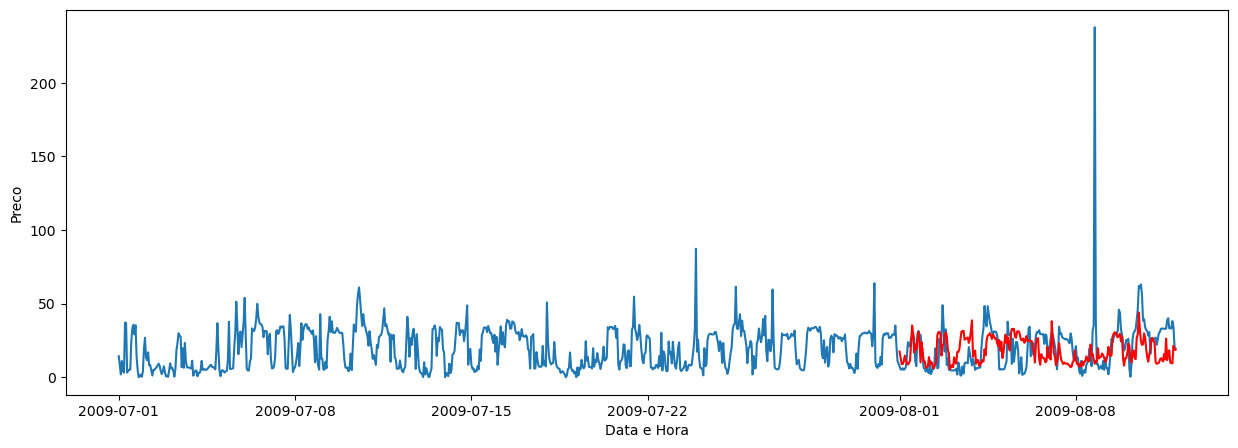

In [102]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_t_validacao, df_previsto_MA_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()